PUNTI FISSI E LA LORO STABILITA'

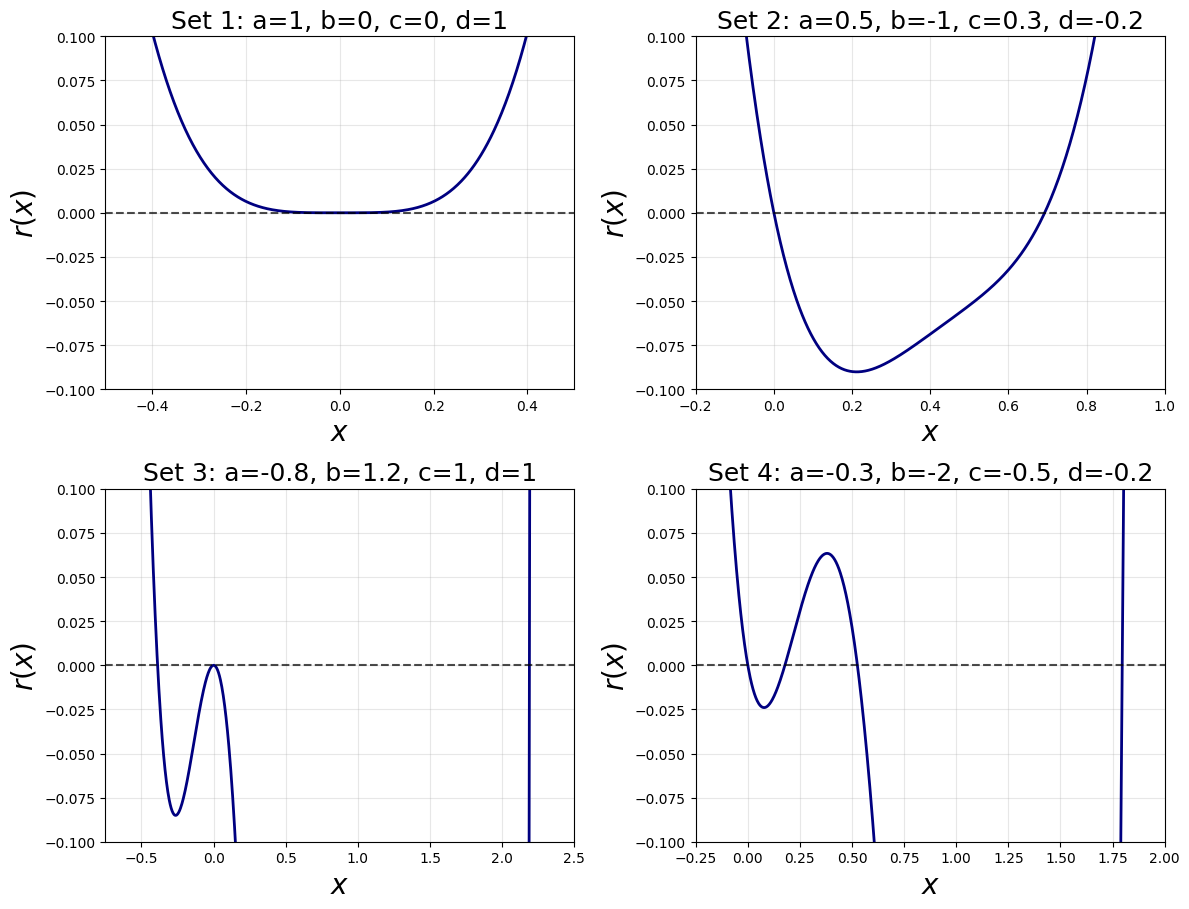

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def r_function(x, a, b, c, d):
    """Definisce la funzione r(x) della mappa di Tinkerbell."""
    termine1 = (2*x + d - 1)**2 * (x**2 + (a - 1)*x)
    termine2 = - (c**2 * x**2)
    termine3 = - (b * c * (2*x + d - 1) * x)
    return termine1 + termine2 + termine3

def plot_confronto_parametri():
    # --- 1. SET DI PARAMETRI ---
    set_parametri = [
        (1, 0, 0, 1),           # Set 1
        (0.5, -1, 0.3, -0.2),   # Set 2
        (-0.8, 1.2, 1, 1),      # Set 3
        (-0.3, -2, -0.5, -0.2)  # Set 4
    ]

    # --- 2. LIMITI PERSONALIZZATI PER OGNI GRAFICO ---
    # Formato: (xmin, xmax, ymin, ymax)
    limiti_assi = [
        (-0.5, 0.5, -0.1, 0.1),   # Limiti per Set 1
        (-0.2, 1, -0.1, 0.1),   # Limiti per Set 2
        (-0.75, 2.5, -0.1, 0.1),   # Limiti per Set 3
        (-0.25, 2, -0.1, 0.1)    # Limiti per Set 4
    ]

    fig, axes = plt.subplots(2, 2, figsize=(12, 10))

    axes_flat = axes.flatten()

    for i, params in enumerate(set_parametri):
        a, b, c, d = params

        # Recupero i limiti specifici per questo subplot
        xmin, xmax, ymin, ymax = limiti_assi[i]

        # Genero i punti x basandomi sui limiti specifici del grafico
        x = np.linspace(xmin, xmax, 1000)
        y = r_function(x, a, b, c, d)

        ax = axes_flat[i]
        ax.plot(x, y, color='navy', lw=2)
        ax.axhline(0, color='black', linestyle='--', alpha=0.7)

        # Applico i limiti personalizzati
        ax.set_xlim(xmin, xmax)
        ax.set_ylim(ymin, ymax)

        ax.set_title(f'Set {i+1}: a={a}, b={b}, c={c}, d={d}', fontsize=18)
        ax.set_xlabel('$x$', fontsize=20)
        ax.set_ylabel('$r(x)$', fontsize=20)
        ax.grid(True, alpha=0.3)

    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

if __name__ == "__main__":
    plot_confronto_parametri()


Punto fisso 1: (x*, y*) = (-0.712054, 0.370070)
  λ1 = 0.043313   |λ1| = 0.043313
  λ2 = -1.391530   |λ2| = 1.391530
  → instabile (sella)

Punto fisso 2: (x*, y*) = (0.000000, -0.000000)
  λ1 = 1.780776   |λ1| = 1.780776
  λ2 = -0.280776   |λ2| = 0.280776
  → instabile (sella)

Punto fisso 3: (x*, y*) = (0.168168, -1.027523)
  λ1 = 1.086336+1.777840j   |λ1| = 2.083468
  λ2 = 1.086336-1.777840j   |λ2| = 2.083468
  → instabile (fuoco repulsivo)

Punto fisso 4: (x*, y*) = (1.043886, 0.657453)
  λ1 = 2.837772+0.816382j   |λ1| = 2.952868
  λ2 = 2.837772-0.816382j   |λ2| = 2.952868
  → instabile (fuoco repulsivo)


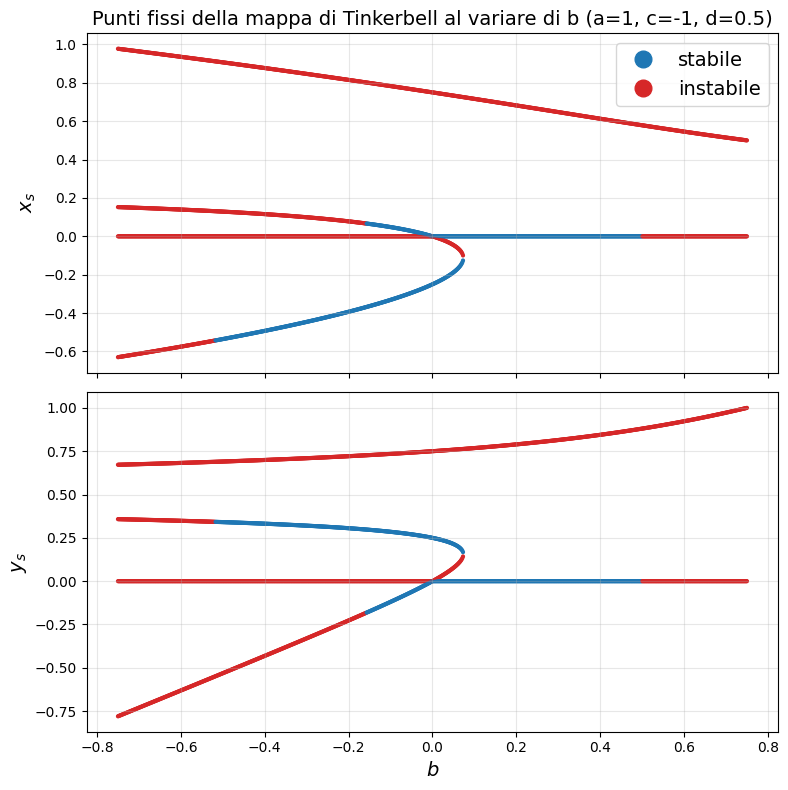

In [99]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from numpy.polynomial import Polynomial

# Mappa di Tinkerbell:
#   x_{n+1} = x^2 - y^2 + a x + b y
#   y_{n+1} = 2 x y + c x + d y


def tinkerbell(x, y, a, b, c, d):
    """Applica una volta la mappa di Tinkerbell."""
    return x**2 - y**2 + a*x + b*y, 2*x*y + c*x + d*y


def r_function(x, a, b, c, d):
    """Definisce la funzione r(x) della mappa di Tinkerbell."""
    termine1 = (2*x + d - 1)**2 * (x**2 + (a - 1)*x)
    termine2 = - (c**2 * x**2)
    termine3 = - (b * c * (2*x + d - 1) * x)
    return termine1 + termine2 + termine3


def jacobiana(x, y, a, b, c, d):
    """Matrice jacobiana della mappa nel punto (x, y)."""
    return np.array([[2*x + a, -2*y + b],
                     [2*y + c,  2*x + d]])


def punti_fissi(a, b, c, d, tol_im=1e-6, tol_res=1e-7, verbose=False):
    """Trova tutti i punti fissi reali della mappa di Tinkerbell,
    inclusi quelli del caso degenere c(d-1) = 0."""
    punti = []

    def aggiungi(x, y):
        """Aggiunge (x, y) se è davvero un punto fisso e non è un duplicato."""
        xn, yn = tinkerbell(x, y, a, b, c, d)
        if np.hypot(xn - x, yn - y) > tol_res:
            if verbose:
                print(f"Candidato ({x:.6f}, {y:.6f}) scartato.")
            return
        for xp, yp in punti:
            if np.hypot(x - xp, y - yp) < 1e-6:
                return
        punti.append((x, y))

    x0 = (1 - d) / 2  # valore che annulla 2x + d - 1

    # --- Caso generico: radici di r(x) con 2x+d-1 != 0 ---
    X = Polynomial([0, 1])
    radici = r_function(X, a, b, c, d).roots()
    for x in radici[np.abs(radici.imag) < tol_im].real:
        A = 2*x + d - 1
        if abs(A) < 1e-6:
            continue          # gestito sotto
        aggiungi(x, -c * x / A)

    # --- Caso degenere: x = x0 è ammesso solo se c(d-1) = 0 ---
    if abs(c * (d - 1)) < 1e-12:
        # y dalla prima equazione: y^2 - b y - (x0^2 + (a-1) x0) = 0
        for y in np.roots([1, -b, -(x0**2 + (a - 1)*x0)]):
            if abs(y.imag) < tol_im:
                aggiungi(x0, y.real)
        if verbose:
            print(f"Caso degenere: considerato x0 = {x0:.6f}")

    return punti



def classifica(autovalori, tol=1e-9):
    """Classifica la stabilità di un punto fisso di una mappa discreta."""
    moduli = np.abs(autovalori)
    if np.any(np.abs(moduli - 1) < tol):
        return "non iperbolico (|λ| = 1)"
    complessi = np.any(np.abs(autovalori.imag) > tol)
    if np.all(moduli < 1):
        return "stabile (fuoco attrattivo)" if complessi else "stabile (nodo attrattivo)"
    if np.all(moduli > 1):
        return "instabile (fuoco repulsivo)" if complessi else "instabile (nodo repulsivo)"
    return "instabile (sella)"

def scansione_a(b, c, d, a_valori):
    """Per ogni a calcola i punti fissi, il raggio spettrale e la stabilità."""
    dati = []  # righe: (a, x*, y*, max|λ|, stabile)
    for a in a_valori:
        for x, y in punti_fissi(a, b, c, d):
            lam = np.linalg.eigvals(jacobiana(x, y, a, b, c, d))
            rho = np.max(np.abs(lam))
            dati.append((a, x, y, rho, rho < 1))
    return np.array(dati)

def scansione_b(a, c, d, b_valori):
    """Per ogni b calcola i punti fissi, il raggio spettrale e la stabilità."""
    dati = []  # righe: (b, x*, y*, max|λ|, stabile)
    for b in b_valori:
        for x, y in punti_fissi(a, b, c, d):
            lam = np.linalg.eigvals(jacobiana(x, y, a, b, c, d))
            rho = np.max(np.abs(lam))
            dati.append((b, x, y, rho, rho < 1))
    return np.array(dati)

def scansione_c(a, b, d, c_valori):
    """Per ogni c calcola i punti fissi, il raggio spettrale e la stabilità."""
    dati = []  # righe: (c, x*, y*, max|λ|, stabile)
    for c in c_valori:
        for x, y in punti_fissi(a, b, c, d):
            lam = np.linalg.eigvals(jacobiana(x, y, a, b, c, d))
            rho = np.max(np.abs(lam))
            dati.append((c, x, y, rho, rho < 1))
    return np.array(dati)

def scansione_d(a, b, c, d_valori):
    """Per ogni d calcola i punti fissi, il raggio spettrale e la stabilità."""
    dati = []  # righe: (d, x*, y*, max|λ|, stabile)
    for d in d_valori:
        for x, y in punti_fissi(a, b, c, d):
            lam = np.linalg.eigvals(jacobiana(x, y, a, b, c, d))
            rho = np.max(np.abs(lam))
            dati.append((d, x, y, rho, rho < 1))
    return np.array(dati)


def plot_stabilita(dati, a, b, c, d):
    b, x, y, rho, stab = dati.T
    stab = stab.astype(bool)
    colori = np.where(stab, "tab:blue", "tab:red")

    fig, ax = plt.subplots(2, 1, figsize=(8, 8), sharex=True)

    ax[0].scatter(b, x, c=colori, s=4)
    ax[0].set_ylabel(r"$x_s$", fontsize=14)

    ax[1].scatter(b, y, c=colori, s=4)
    ax[1].set_ylabel(r"$y_s$", fontsize=14)
    #ax[1].set_ylim(-0.5, 0.5)
    ax[1].set_xlabel(r"$b$", fontsize=14)

    legenda = [
        Line2D([], [], marker="o", ls="", color="tab:blue", label="stabile"),
        Line2D([], [], marker="o", ls="", color="tab:red", label="instabile"),
    ]
    ax[0].legend(handles=legenda, loc="best", fontsize=14, markerscale=2)
    ax[0].set_title(f"Punti fissi della mappa di Tinkerbell al variare di b "
                    f"(a={a}, c={c}, d={d})", fontsize=14)

    for asse in ax:
        asse.grid(alpha=0.3)

    fig.tight_layout()
    plt.show()

def plot_stabbilita(dati, a, b, c, d):
    b_val, x, y, rho, stab = dati.T
    stab = stab.astype(bool)
    colori = np.where(stab, "tab:blue", "tab:red")

    fig, ax = plt.subplots(figsize=(8, 6))

    ax.scatter(b_val, x, c=colori, s=4)
    ax.set_ylabel(r"$x_s$", fontsize=14)
    ax.set_xlabel(r"$b$", fontsize=14)

    legenda = [
        Line2D([], [], marker="o", ls="", color="tab:blue", label="stabile"),
        Line2D([], [], marker="o", ls="", color="tab:red", label="instabile"),
    ]
    ax.legend(handles=legenda, loc="best", fontsize=14, markerscale=2)
    ax.set_title(f"Punti fissi della mappa di Tinkerbell al variare di b "
                 f"(a={a}, c={c}, d={d})", fontsize=14)

    ax.grid(alpha=0.3)

    fig.tight_layout()
    plt.show()



if __name__ == "__main__":
    # Parametri classici della mappa di Tinkerbell
    a, b, c, d = 1, -1, -1, 0.5

    # --- Analisi per il valore di b fissato ---
    for i, (x, y) in enumerate(punti_fissi(a, b, c, d, verbose=True), start=1):
        J = jacobiana(x, y, a, b, c, d)
        lam = np.linalg.eigvals(J)
        print(f"\nPunto fisso {i}: (x*, y*) = ({x:.6f}, {y:.6f})")
        for k, l in enumerate(lam, start=1):
            print(f"  λ{k} = {l:.6f}   |λ{k}| = {abs(l):.6f}")
        print("  →", classifica(lam))

    # --- Scansione in b ---
    b_valori = np.linspace(-0.75, 0.75, 1000)
    dati = scansione_b(a, c, d, b_valori)
    plot_stabilita(dati, a, b, c, d)


PLOT DELLE ORBITE E BIFORCAZIONI


Punto fisso 1: (x*, y*) = (0.000000, -0.000000)
  λ1 = 0.788854   |λ1| = 0.788854
  λ2 = -2.788854   |λ2| = 2.788854
  → instabile (sella)

Punto fisso 2: (x*, y*) = (0.414024, -0.099240)
  λ1 = 1.173761   |λ1| = 1.173761
  λ2 = -1.517666   |λ2| = 1.517666
  → instabile (nodo repulsivo)

Punto fisso 3: (x*, y*) = (0.898849, -0.280688)
  λ1 = 0.797697+0.965662j   |λ1| = 1.252527
  λ2 = 0.797697-0.965662j   |λ2| = 1.252527
  → instabile (fuoco repulsivo)

Punto fisso 4: (x*, y*) = (2.687128, 7.179928)
  λ1 = 4.374256+10.264426j   |λ1| = 11.157623
  λ2 = 4.374256-10.264426j   |λ2| = 11.157623
  → instabile (fuoco repulsivo)


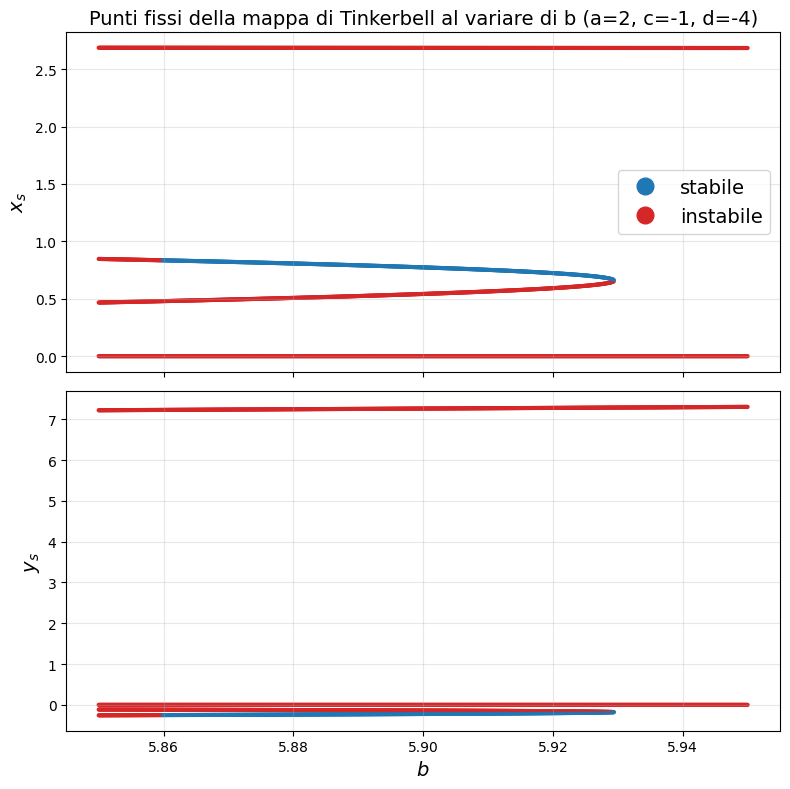

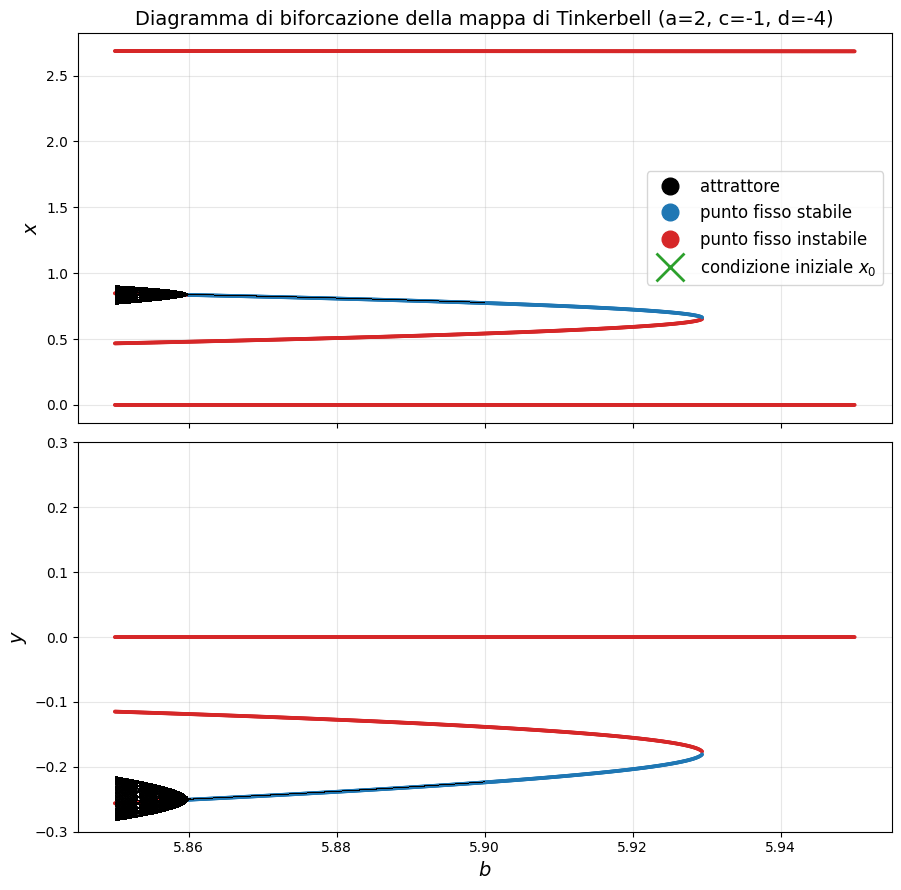

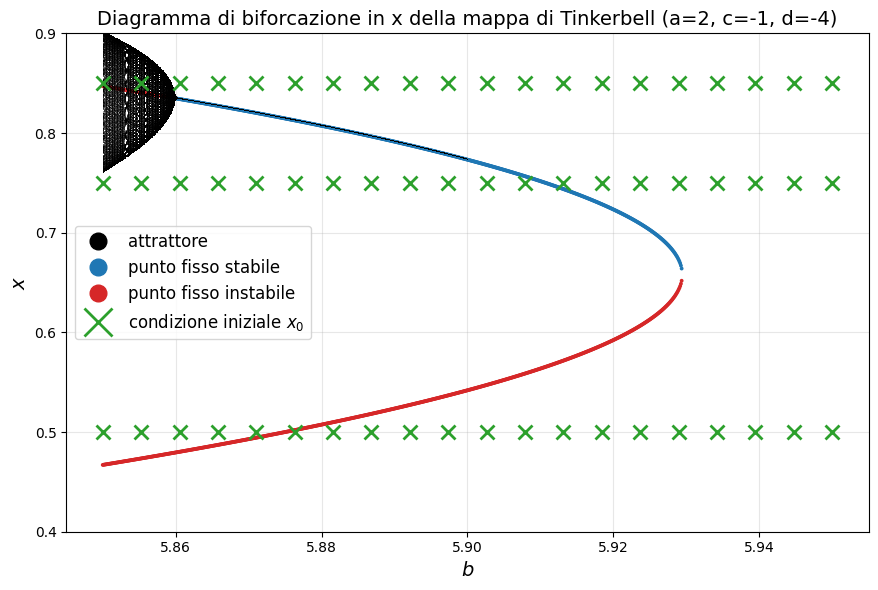

In [24]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from numpy.polynomial import Polynomial

# Mappa di Tinkerbell:
#   x_{n+1} = x^2 - y^2 + a x + b y
#   y_{n+1} = 2 x y + c x + d y


def tinkerbell(x, y, a, b, c, d):
    """Applica una volta la mappa di Tinkerbell."""
    return x**2 - y**2 + a*x + b*y, 2*x*y + c*x + d*y


def r_function(x, a, b, c, d):
    """Definisce la funzione r(x) della mappa di Tinkerbell."""
    termine1 = (2*x + d - 1)**2 * (x**2 + (a - 1)*x)
    termine2 = - (c**2 * x**2)
    termine3 = - (b * c * (2*x + d - 1) * x)
    return termine1 + termine2 + termine3


def jacobiana(x, y, a, b, c, d):
    """Matrice jacobiana della mappa nel punto (x, y)."""
    return np.array([[2*x + a, -2*y + b],
                     [2*y + c,  2*x + d]])


def punti_fissi(a, b, c, d, tol_im=1e-6, tol_res=1e-7, verbose=False):
    """Trova tutti i punti fissi reali della mappa di Tinkerbell,
    inclusi quelli del caso degenere c(d-1) = 0."""
    punti = []

    def aggiungi(x, y):
        xn, yn = tinkerbell(x, y, a, b, c, d)
        if np.hypot(xn - x, yn - y) > tol_res:
            if verbose:
                print(f"Candidato ({x:.6f}, {y:.6f}) scartato.")
            return
        for xp, yp in punti:
            if np.hypot(x - xp, y - yp) < 1e-6:
                return
        punti.append((x, y))

    x0 = (1 - d) / 2  # valore che annulla 2x + d - 1

    # --- Caso generico ---
    X = Polynomial([0, 1])
    radici = r_function(X, a, b, c, d).roots()
    for x in radici[np.abs(radici.imag) < tol_im].real:
        A = 2*x + d - 1
        if abs(A) < 1e-6:
            continue
        aggiungi(x, -c * x / A)

    # --- Caso degenere ---
    if abs(c * (d - 1)) < 1e-12:
        for y in np.roots([1, -b, -(x0**2 + (a - 1)*x0)]):
            if abs(y.imag) < tol_im:
                aggiungi(x0, y.real)
        if verbose:
            print(f"Caso degenere: considerato x0 = {x0:.6f}")

    return punti


def classifica(autovalori, tol=1e-9):
    """Classifica la stabilità di un punto fisso di una mappa discreta."""
    moduli = np.abs(autovalori)
    if np.any(np.abs(moduli - 1) < tol):
        return "non iperbolico (|λ| = 1)"
    complessi = np.any(np.abs(autovalori.imag) > tol)
    if np.all(moduli < 1):
        return "stabile (fuoco attrattivo)" if complessi else "stabile (nodo attrattivo)"
    if np.all(moduli > 1):
        return "instabile (fuoco repulsivo)" if complessi else "instabile (nodo repulsivo)"
    return "instabile (sella)"


def scansione_b(a, c, d, b_valori):
    """Per ogni b calcola i punti fissi, il raggio spettrale e la stabilità."""
    dati = []  # righe: (b, x*, y*, max|λ|, stabile)
    for b in b_valori:
        for x, y in punti_fissi(a, b, c, d):
            lam = np.linalg.eigvals(jacobiana(x, y, a, b, c, d))
            rho = np.max(np.abs(lam))
            dati.append((b, x, y, rho, rho < 1))
    return np.array(dati)


def plot_stabilita(dati, a, b, c, d):
    b_val, x, y, rho, stab = dati.T
    stab = stab.astype(bool)
    colori = np.where(stab, "tab:blue", "tab:red")

    fig, ax = plt.subplots(2, 1, figsize=(8, 8), sharex=True)
    ax[0].scatter(b_val, x, c=colori, s=4)
    ax[0].set_ylabel(r"$x_s$", fontsize=14)
    ax[1].scatter(b_val, y, c=colori, s=4)
    ax[1].set_ylabel(r"$y_s$", fontsize=14)
    ax[1].set_xlabel(r"$b$", fontsize=14)

    legenda = [
        Line2D([], [], marker="o", ls="", color="tab:blue", label="stabile"),
        Line2D([], [], marker="o", ls="", color="tab:red", label="instabile"),
    ]
    ax[0].legend(handles=legenda, loc="best", fontsize=14, markerscale=2)
    ax[0].set_title(f"Punti fissi della mappa di Tinkerbell al variare di b "
                    f"(a={a}, c={c}, d={d})", fontsize=14)
    for asse in ax:
        asse.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()


def diagramma_biforcazione(a, c, d, b_valori, n_trans=2000, n_plot=300,
                           condizioni_iniziali=((-0.72, -0.64),),
                           soglia=1e3):
    """Diagramma di biforcazione al variare di b (orbite divergenti scartate)."""
    b = np.asarray(b_valori, dtype=float)
    B_tot, X_tot, Y_tot = [], [], []

    for x0, y0 in condizioni_iniziali:
        x = np.full_like(b, x0)
        y = np.full_like(b, y0)
        vive = np.ones(b.size, dtype=bool)

        def passo(x, y, vive):
            x, y = tinkerbell(x, y, a, b, c, d)
            vive &= (np.isfinite(x) & np.isfinite(y)
                     & (np.abs(x) < soglia) & (np.abs(y) < soglia))
            x = np.where(vive, x, 0.0)
            y = np.where(vive, y, 0.0)
            return x, y, vive

        with np.errstate(over="ignore", invalid="ignore"):
            for _ in range(n_trans):
                x, y, vive = passo(x, y, vive)
            Xs = np.empty((n_plot, b.size))
            Ys = np.empty((n_plot, b.size))
            for k in range(n_plot):
                x, y, vive = passo(x, y, vive)
                Xs[k], Ys[k] = x, y

        maschera = np.broadcast_to(vive, Xs.shape)
        Bs = np.broadcast_to(b, Xs.shape)
        B_tot.append(Bs[maschera])
        X_tot.append(Xs[maschera])
        Y_tot.append(Ys[maschera])

    return np.concatenate(B_tot), np.concatenate(X_tot), np.concatenate(Y_tot)


def legenda_bif():
    return [
        Line2D([], [], marker="o", ls="", color="black", label="attrattore"),
        Line2D([], [], marker="o", ls="", color="tab:blue", label="punto fisso stabile"),
        Line2D([], [], marker="o", ls="", color="tab:red", label="punto fisso instabile"),
        Line2D([], [], marker="x", ls="", color="tab:green", markersize=10, markeredgewidth=2, label="condizione iniziale $x_0$"),

    ]


def plot_biforcazione(bif, dati_fissi, a, c, d):
    """Diagramma di biforcazione in x e y con i punti fissi sovrapposti."""
    B, X, Y = bif
    b_f, x_f, y_f, rho, stab = dati_fissi.T
    colori = np.where(stab.astype(bool), "tab:blue", "tab:red")

    fig, ax = plt.subplots(2, 1, figsize=(9, 9), sharex=True)
    for asse, V, Vf, etichetta in ((ax[0], X, x_f, r"$x$"),
                                   (ax[1], Y, y_f, r"$y$")):
        asse.scatter(b_f, Vf, c=colori, s=3, zorder=2)
        asse.plot(B, V, ",", color="black", alpha=0.4, rasterized=True, zorder=3)
        asse.set_ylabel(etichetta, fontsize=14)
        asse.grid(alpha=0.3, zorder=0)

    ax[1].set_xlabel(r"$b$", fontsize=14)
    ax[0].legend(handles=legenda_bif(), loc="best", fontsize=12, markerscale=2)
    ax[0].set_title(f"Diagramma di biforcazione della mappa di Tinkerbell "
                    f"(a={a}, c={c}, d={d})", fontsize=14)
    fig.tight_layout()
    ax[1].set_ylim(-0.3,0.3)
    plt.show()


def plot_biforcazione_x(bif, dati_fissi, a, c, d, ci):
    """Solo asse x: diagramma di biforcazione (in primo piano) e punti fissi."""
    B, X, _ = bif
    b_f, x_f, y_f, rho, stab = dati_fissi.T
    colori = np.where(stab.astype(bool), "tab:blue", "tab:red")

    fig, ax = plt.subplots(figsize=(9, 6))
    ax.scatter(b_f, x_f, c=colori, s=3, zorder=2)
    ax.plot(B, X, ",", color="black", alpha=0.4, rasterized=True, zorder=3)
    for x0, y0 in ci:
        ax.plot(np.linspace(b_f.min(), b_f.max(), 20), np.full(20, x0), "x", color="tab:green", markersize=10, markeredgewidth=2, zorder=4)


    ax.set_xlabel(r"$b$", fontsize=14)
    ax.set_ylabel(r"$x$", fontsize=14)
    ax.set_title(f"Diagramma di biforcazione in x della mappa di Tinkerbell "
                 f"(a={a}, c={c}, d={d})", fontsize=14)
    ax.legend(handles=legenda_bif(), loc="best", fontsize=12, markerscale=2)
    
    ax.grid(alpha=0.3, zorder=0)
    fig.tight_layout()
    ax.set_ylim(0.4,0.9)
    plt.show()


if __name__ == "__main__":
    a, b, c, d = 2, 5.8, -1, -4

    # --- Analisi per il valore di b fissato ---
    for i, (x, y) in enumerate(punti_fissi(a, b, c, d, verbose=True), start=1):
        J = jacobiana(x, y, a, b, c, d)
        lam = np.linalg.eigvals(J)
        print(f"\nPunto fisso {i}: (x*, y*) = ({x:.6f}, {y:.6f})")
        for k, l in enumerate(lam, start=1):
            print(f"  λ{k} = {l:.6f}   |λ{k}| = {abs(l):.6f}")
        print("  →", classifica(lam))

    # --- Scansione dei punti fissi in b ---
    b_valori = np.linspace(5.850, 5.950, 1000)
    dati = scansione_b(a, c, d, b_valori)
    plot_stabilita(dati, a, b, c, d)

    # --- Diagramma di biforcazione in b ---
    ci = [(-0.72, -0.64), (0.1, 0.1), (-0.3, 0.2), (0.75, -0.25), (0.5, -0.11), (0.85, 0.1)]
    bif = diagramma_biforcazione(a, c, d, b_valori,
                                 n_trans=2000, n_plot=300,
                                 condizioni_iniziali=ci)
    plot_biforcazione(bif, dati, a, c, d)

    # --- Nuovo plot: solo asse x con i punti fissi ---
    plot_biforcazione_x(bif, dati, a, c, d, ci)



Punto fisso 1: (x*, y*) = (-0.469593, -0.824436)
  λ1 = 0.547918   |λ1| = 0.547918
  λ2 = -0.726289   |λ2| = 0.726289
  → stabile (nodo attrattivo)

Punto fisso 2: (x*, y*) = (-0.121833, -0.549210)
  λ1 = 1.342557   |λ1| = 1.342557
  λ2 = -0.129888   |λ2| = 0.129888
  → instabile (sella)

Punto fisso 3: (x*, y*) = (0.000000, 0.000000)
  λ1 = 0.850000+0.998749j   |λ1| = 1.311488
  λ2 = 0.850000-0.998749j   |λ2| = 1.311488
  → instabile (fuoco repulsivo)

Punto fisso 4: (x*, y*) = (0.891425, -1.126354)
  λ1 = 2.632851+0.663645j   |λ1| = 2.715203
  λ2 = 2.632851-0.663645j   |λ2| = 2.715203
  → instabile (fuoco repulsivo)


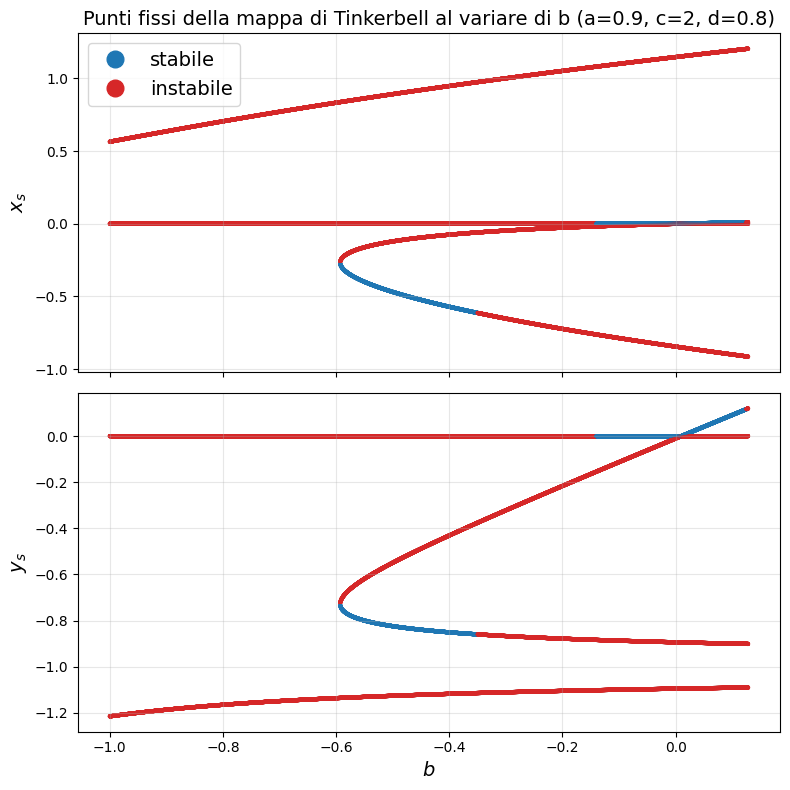


Ripartenze scansione in avanti:    3612
Ripartenze scansione all'indietro: 3610


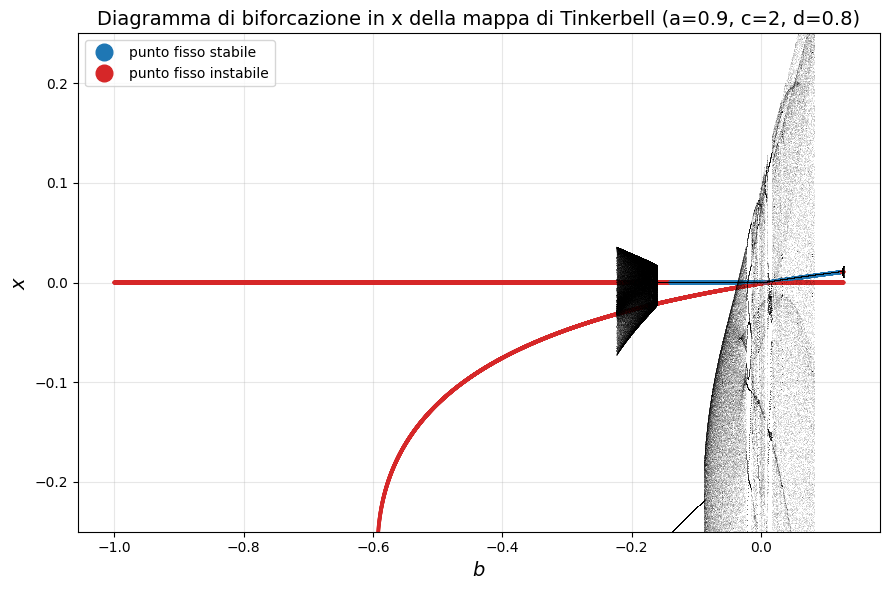

In [82]:
######################################
# Versione con la continuazione in b #
######################################

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from numpy.polynomial import Polynomial

# Mappa di Tinkerbell:
#   x_{n+1} = x^2 - y^2 + a x + b y
#   y_{n+1} = 2 x y + c x + d y


def tinkerbell(x, y, a, b, c, d):
    """Applica una volta la mappa di Tinkerbell."""
    return x**2 - y**2 + a*x + b*y, 2*x*y + c*x + d*y


def r_function(x, a, b, c, d):
    """Definisce la funzione r(x) della mappa di Tinkerbell."""
    termine1 = (2*x + d - 1)**2 * (x**2 + (a - 1)*x)
    termine2 = - (c**2 * x**2)
    termine3 = - (b * c * (2*x + d - 1) * x)
    return termine1 + termine2 + termine3


def jacobiana(x, y, a, b, c, d):
    """Matrice jacobiana della mappa nel punto (x, y)."""
    return np.array([[2*x + a, -2*y + b],
                     [2*y + c,  2*x + d]])


def punti_fissi(a, b, c, d, tol_im=1e-6, tol_res=1e-7, verbose=False):
    """Trova tutti i punti fissi reali della mappa di Tinkerbell,
    inclusi quelli del caso degenere c(d-1) = 0."""
    punti = []

    def aggiungi(x, y):
        xn, yn = tinkerbell(x, y, a, b, c, d)
        if np.hypot(xn - x, yn - y) > tol_res:
            if verbose:
                print(f"Candidato ({x:.6f}, {y:.6f}) scartato.")
            return
        for xp, yp in punti:
            if np.hypot(x - xp, y - yp) < 1e-6:
                return
        punti.append((x, y))

    x0 = (1 - d) / 2  # valore che annulla 2x + d - 1

    # --- Caso generico ---
    X = Polynomial([0, 1])
    radici = r_function(X, a, b, c, d).roots()
    for x in radici[np.abs(radici.imag) < tol_im].real:
        A = 2*x + d - 1
        if abs(A) < 1e-6:
            continue
        aggiungi(x, -c * x / A)

    # --- Caso degenere ---
    if abs(c * (d - 1)) < 1e-12:
        for y in np.roots([1, -b, -(x0**2 + (a - 1)*x0)]):
            if abs(y.imag) < tol_im:
                aggiungi(x0, y.real)
        if verbose:
            print(f"Caso degenere: considerato x0 = {x0:.6f}")

    return punti


def classifica(autovalori, tol=1e-9):
    """Classifica la stabilità di un punto fisso di una mappa discreta."""
    moduli = np.abs(autovalori)
    if np.any(np.abs(moduli - 1) < tol):
        return "non iperbolico (|λ| = 1)"
    complessi = np.any(np.abs(autovalori.imag) > tol)
    if np.all(moduli < 1):
        return "stabile (fuoco attrattivo)" if complessi else "stabile (nodo attrattivo)"
    if np.all(moduli > 1):
        return "instabile (fuoco repulsivo)" if complessi else "instabile (nodo repulsivo)"
    return "instabile (sella)"


def scansione_b(a, c, d, b_valori):
    """Per ogni b calcola i punti fissi, il raggio spettrale e la stabilità."""
    dati = []  # righe: (b, x*, y*, max|λ|, stabile)
    for b in b_valori:
        for x, y in punti_fissi(a, b, c, d):
            lam = np.linalg.eigvals(jacobiana(x, y, a, b, c, d))
            rho = np.max(np.abs(lam))
            dati.append((b, x, y, rho, rho < 1))
    return np.array(dati)


def ci_iniziale(a, b, c, d, eps=1e-3):
    """Condizione iniziale vicino a un punto fisso stabile, se esiste;
    altrimenti vicino all'origine."""
    for x, y in punti_fissi(a, b, c, d):
        lam = np.linalg.eigvals(jacobiana(x, y, a, b, c, d))
        if np.max(np.abs(lam)) < 1:
            return x + eps, y + eps
    return eps, eps


def continuazione(a, c, d, b_valori, n_trans=1000, n_plot=200,
                  soglia=1e3, ci=None, n_salta=10, n_salta_fine=2):
    """n_salta: b scartati dopo ogni (ri)partenza.
    n_salta_fine: b scartati prima di ogni divergenza."""
    B_tot, X_tot, Y_tot = [], [], []
    partenze = []

    x, y = ci if ci is not None else ci_iniziale(a, b_valori[0], c, d)
    partenze.append((b_valori[0], x, y))
    serve_ripartenza = False
    da_saltare = n_salta
    salvati_segmento = 0          # blocchi salvati dall'ultima partenza

    for b in b_valori:
        if serve_ripartenza:
            x, y = ci_iniziale(a, b, c, d)
            partenze.append((b, x, y))
            serve_ripartenza = False
            da_saltare = n_salta
            salvati_segmento = 0

        diverge = False
        Xs = np.empty(n_plot)
        Ys = np.empty(n_plot)
        for k in range(n_trans + n_plot):
            x, y = tinkerbell(x, y, a, b, c, d)
            if not (abs(x) < soglia and abs(y) < soglia):
                diverge = True
                break
            if k >= n_trans:
                Xs[k - n_trans], Ys[k - n_trans] = x, y

        if diverge:
            # togli gli ultimi blocchi del segmento: erano già in fuga
            n_via = min(n_salta_fine, salvati_segmento)
            for _ in range(n_via):
                B_tot.pop(); X_tot.pop(); Y_tot.pop()
            salvati_segmento = 0
            serve_ripartenza = True
            continue

        if da_saltare > 0:
            da_saltare -= 1
            continue

        B_tot.append(np.full(n_plot, b))
        X_tot.append(Xs)
        Y_tot.append(Ys)
        salvati_segmento += 1

    if not B_tot:
        return (np.array([]),) * 3, partenze
    return (np.concatenate(B_tot), np.concatenate(X_tot),
            np.concatenate(Y_tot)), partenze



def plot_stabilita(dati, a, c, d):
    b_val, x, y, rho, stab = dati.T
    colori = np.where(stab.astype(bool), "tab:blue", "tab:red")

    fig, ax = plt.subplots(2, 1, figsize=(8, 8), sharex=True)
    ax[0].scatter(b_val, x, c=colori, s=4)
    ax[0].set_ylabel(r"$x_s$", fontsize=14)
    ax[1].scatter(b_val, y, c=colori, s=4)
    ax[1].set_ylabel(r"$y_s$", fontsize=14)
    ax[1].set_xlabel(r"$b$", fontsize=14)

    legenda = [
        Line2D([], [], marker="o", ls="", color="tab:blue", label="stabile"),
        Line2D([], [], marker="o", ls="", color="tab:red", label="instabile"),
    ]
    ax[0].legend(handles=legenda, loc="best", fontsize=14, markerscale=2)
    ax[0].set_title(f"Punti fissi della mappa di Tinkerbell al variare di b "
                    f"(a={a}, c={c}, d={d})", fontsize=14)
    for asse in ax:
        asse.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()


def legenda_bif():
    return [
        #Line2D([], [], marker="o", ls="", color="black", label="attrattore"),
        #Line2D([], [], marker="o", ls="", color="tab:gray", label="attrattore (b decrescente)"),
        Line2D([], [], marker="o", ls="", color="tab:blue", label="punto fisso stabile"),
        Line2D([], [], marker="o", ls="", color="tab:red", label="punto fisso instabile"),
    ]


def disegna(asse, avanti, indietro, dati_fissi, partenze, comp):
    """comp = 1 per x, 2 per y."""
    b_f = dati_fissi[:, 0]
    V_f = dati_fissi[:, comp]
    colori = np.where(dati_fissi[:, 4].astype(bool), "tab:blue", "tab:red")

    asse.scatter(b_f, V_f, c=colori, s=3, zorder=2)
    asse.plot(indietro[0], indietro[comp], ",", color="black", alpha=0.1, rasterized=False, zorder=3)
    asse.plot(avanti[0], avanti[comp], ",", color="black", alpha=0.1, rasterized=False, zorder=4)
    #for p in partenze:
        #asse.plot(p[0], p[comp], "x", color="tab:green", markersize=10, markeredgewidth=2, zorder=5)
    asse.grid(alpha=0.3, zorder=0)


def plot_biforcazione(avanti, indietro, dati_fissi, partenze, a, c, d):
    """Diagramma di biforcazione in x e y con i punti fissi."""
    fig, ax = plt.subplots(2, 1, figsize=(9, 9), sharex=True)
    disegna(ax[0], avanti, indietro, dati_fissi, partenze, 1)
    disegna(ax[1], avanti, indietro, dati_fissi, partenze, 2)
    ax[0].set_ylabel(r"$x$", fontsize=14)
    ax[1].set_ylabel(r"$y$", fontsize=14)
    ax[1].set_xlabel(r"$b$", fontsize=14)
    ax[0].legend(handles=legenda_bif(), loc="best", fontsize=10, markerscale=2)
    ax[0].set_title(f"Diagramma di biforcazione della mappa di Tinkerbell "
                    f"(a={a}, c={c}, d={d})", fontsize=14)
    fig.tight_layout()
    plt.show()


def plot_biforcazione_x(avanti, indietro, dati_fissi, partenze, a, c, d):
    """Solo asse x: diagramma di biforcazione e punti fissi."""
    fig, ax = plt.subplots(figsize=(9, 6))
    disegna(ax, avanti, indietro, dati_fissi, partenze, 1)
    ax.set_xlabel(r"$b$", fontsize=14)
    ax.set_ylabel(r"$x$", fontsize=14)
    ax.set_title(f"Diagramma di biforcazione in x della mappa di Tinkerbell "
                 f"(a={a}, c={c}, d={d})", fontsize=14)
    ax.legend(handles=legenda_bif(), loc="best", fontsize=10, markerscale=2)
    ax.set_ylim(-0.25,0.25)
    fig.tight_layout()
    plt.show()

if __name__ == "__main__":
    a, b, c, d = 0.9, -0.5, 2, 0.8

    # --- Analisi per il valore di b fissato ---
    for i, (x, y) in enumerate(punti_fissi(a, b, c, d, verbose=True), start=1):
        lam = np.linalg.eigvals(jacobiana(x, y, a, b, c, d))
        print(f"\nPunto fisso {i}: (x*, y*) = ({x:.6f}, {y:.6f})")
        for k, l in enumerate(lam, start=1):
            print(f"  λ{k} = {l:.6f}   |λ{k}| = {abs(l):.6f}")
        print("  →", classifica(lam))

    # --- Scansione dei punti fissi in b ---
    b_valori = np.linspace(-1, 0.128, 10000)
    dati = scansione_b(a, c, d, b_valori)
    plot_stabilita(dati, a, c, d)

    # --- Continuazione in avanti e all'indietro ---
    avanti, part_av = continuazione(a, c, d, b_valori)
    indietro, part_ind = continuazione(a, c, d, b_valori[::-1])
    partenze = np.array(part_av + part_ind)   # colonne: b, x0, y0

    print(f"\nRipartenze scansione in avanti:    {len(part_av)}")
    print(f"Ripartenze scansione all'indietro: {len(part_ind)}")

    #plot_biforcazione(avanti, indietro, dati, partenze, a, c, d)
    plot_biforcazione_x(avanti, indietro, dati, partenze, a, c, d)
